## Invoice

###Page 1

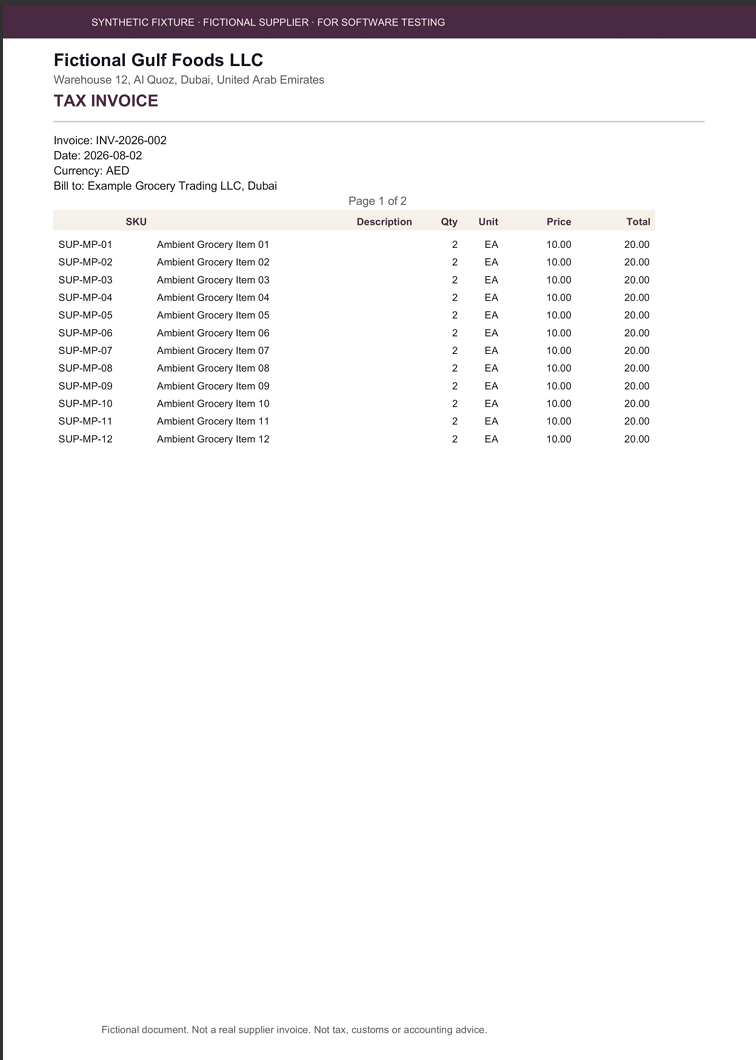

### Page 2

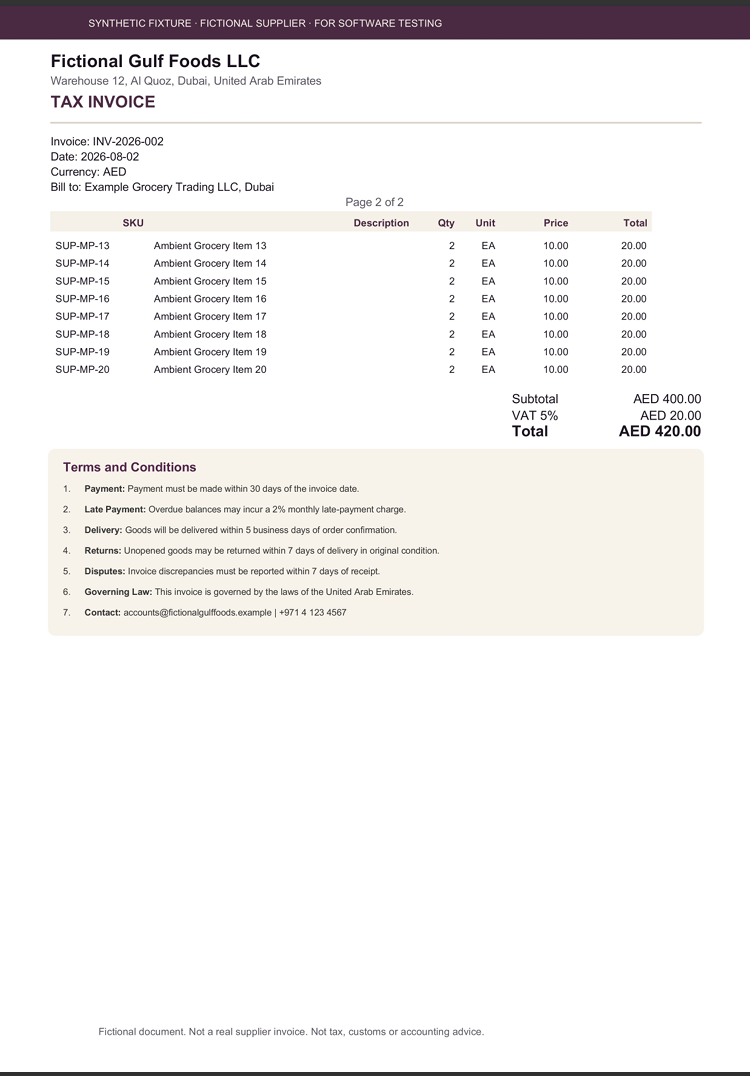


## Connect Google Drive

Mount Google Drive so the notebook can access the invoice files stored in the project folder.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## Loading the Invoices

In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Invoices Docling+RAG"
)

IMAGE_PATH = PROJECT_DIR / "invoice1 img.png"
PDF_PATH = PROJECT_DIR / "T&C invoice1.pdf"

print("Project folder exists:", PROJECT_DIR.exists())
print("PNG exists:", IMAGE_PATH.exists())
print("PDF exists:", PDF_PATH.exists())

print("\nFiles in project folder:")
for file in sorted(PROJECT_DIR.iterdir()):
    print(file.name)


Project folder exists: True
PNG exists: True
PDF exists: True

Files in project folder:
T&C invoice1.pdf
T&C invoice2.pdf
T&C invoice3.pdf
T&C invoice4.pdf
T&C invoice4.png
T&C invoice4_image_extracted.json
T&C invoice4_image_extracted.md
invoice1 img.png
invoice1.pdf
invoice2 img.png
invoice2.pdf
invoice3 img.png
invoice3.pdf
invoice4 img.png
invoice4.pdf
invoice4_image_extracted.json
invoice4_image_extracted.md


## Downloading and Importing Docling and other Necessary Libraries

In [ ]:
%pip install -q docling

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 328.2/328.2 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 98.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.1/183.1 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 82.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.

In [ ]:
from docling.document_converter import DocumentConverter
import json

converter = DocumentConverter()

## Extract Content from the PNG Invoice

In [ ]:
pdf_result = converter.convert(str(PDF_PATH))

print("PDF processed successfully.")
print("Input file:", PDF_PATH.name)

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/conv.py:548: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /pytorch/aten/src/ATen/native/Convolution.cpp:1024.)
  return F.conv2d(


PDF processed successfully.
Input file: T&C invoice1.pdf


## Inspcecting the Extracted Elements

In [ ]:
pdf_markdown = pdf_result.document.export_to_markdown()

print(pdf_markdown)

## Fictional Gulf Foods LLC

Warehouse 12, Al Quoz, Dubai, United Arab Emirates

## TAXINVOICE

Invoice: INV-2026-002

Date: 2026-08-02

Currency: AED

Bill to: Example Grocery Trading LLC, Dubai

| SKU       |                         | Description   |   Qty | Unit   |   Price |   Total |
|-----------|-------------------------|---------------|-------|--------|---------|---------|
| SUP-MP-01 | Ambient Grocery Item 01 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-02 | Ambient Grocery Item 02 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-03 | Ambient Grocery Item 03 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-04 | Ambient Grocery Item 04 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-05 | Ambient Grocery Item 05 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-06 | Ambient Grocery Item 06 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-07 | Ambient Grocery Item 07 |               |    

## Saving Results to Drive

In [ ]:
markdown_path = PROJECT_DIR / "1PDF_T&C invoice1_extracted.md"
json_path = PROJECT_DIR / "1PDF_T&C invoice1_extracted.json"

# Save Markdown
markdown_path.write_text(
    pdf_markdown,
    encoding="utf-8"
)

# Save structured document data
image_data = pdf_result.document.export_to_dict()

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(image_data, f, indent=2, ensure_ascii=False)

print("Saved Markdown:", markdown_path)
print("Saved JSON:", json_path)

Saved Markdown: /content/drive/MyDrive/Invoices Docling+RAG/1PDF_T&C invoice1_extracted.md
Saved JSON: /content/drive/MyDrive/Invoices Docling+RAG/1PDF_T&C invoice1_extracted.json


## Chunking the Extracted Invoice

Split Docling's extracted Markdown into meaningful sections to prepare the invoice for embedding and retrieval.


In [ ]:

import re

def chunk_invoice(invoice_text, invoice_id, rows_per_chunk=5):
    """Create chunks from invoice metadata, tables, totals and T&C."""

    chunks = []

    def add_chunk(text, section):
        text = text.strip()
        if text:
            chunks.append({
                "invoice_id": invoice_id,
                "chunk_id": f"{invoice_id}_chunk_{len(chunks) + 1}",
                "section": section,
                "text": text
            })

    # Remove page markers and blank lines around page boundaries
    clean_text = re.sub(
        r"(?m)^Page \d+ of \d+\s*$",
        "",
        invoice_text
    )

    # Separate Terms and Conditions
    parts = re.split(
        r"(?m)^## Terms and Conditions\s*$",
        clean_text,
        maxsplit=1
    )
    invoice_body = parts[0].strip()
    terms_body = parts[1].strip() if len(parts) > 1 else ""

    # Extract invoice header before the first Markdown table
    first_table = re.search(r"(?m)^\|.*\|$", invoice_body)
    if not first_table:
        raise ValueError("No Markdown table found.")

    header_text = invoice_body[:first_table.start()].strip()

    # Remove repeated page header from metadata
    header_text = re.sub(
        r"(?m)^## Fictional Gulf Foods LLC\s*$",
        "",
        header_text
    ).strip()

    add_chunk(header_text, "invoice_header")

    # Extract separate Markdown table blocks.
    # Tables are separated by blank lines in the extracted Markdown.
    table_blocks = re.findall(
        r"(?m)(?:^\|.*\|\n?)+",
        invoice_body
    )

    for table_number, table in enumerate(table_blocks, start=1):
        lines = [line.strip() for line in table.splitlines() if line.strip()]

        # Remove Markdown separator rows
        lines = [
            line for line in lines
            if not re.fullmatch(r"\|[\s|:-]+\|", line)
        ]

        if len(lines) < 2:
            continue

        table_header = lines[0]
        data_rows = lines[1:]

        # Exclude rows that repeat the table header
        data_rows = [
            row for row in data_rows
            if row != table_header
        ]

        for start in range(0, len(data_rows), rows_per_chunk):
            row_group = data_rows[start:start + rows_per_chunk]
            chunk_text = "\n".join([table_header] + row_group)

            add_chunk(
                chunk_text,
                f"line_items_table_{table_number}"
            )

    # Extract totals separately
    totals_match = re.search(
        r"(?ms)^\s*Subtotal\b.*?(?=\Z)",
        invoice_body
    )

    if totals_match:
        add_chunk(totals_match.group(), "invoice_totals")

    # Keep each numbered T&C clause intact
    clauses = re.findall(
        r"(?m)^\s*\d+\.\s*.+$",
        terms_body
    )

    for clause in clauses:
        add_chunk(clause, "terms_and_conditions")

    return chunks


chunks = chunk_invoice(
    invoice_text=invoice_text,
    invoice_id="INV-2026-002",
    rows_per_chunk=5
)

print("Total chunks:", len(chunks))

for chunk in chunks:
    print(
        f"\n[{chunk['chunk_id']}] "
        f"{chunk['section']}\n{chunk['text']}"
    )

Total chunks: 14

[INV-2026-002_chunk_1] invoice_header
Warehouse 12, Al Quoz, Dubai, United Arab Emirates

## TAXINVOICE

Invoice: INV-2026-002

Date: 2026-08-02

Currency: AED

Bill to: Example Grocery Trading LLC, Dubai

[INV-2026-002_chunk_2] line_items_table_1
| SKU       |                         | Description   |   Qty | Unit   |   Price |   Total |
| SUP-MP-01 | Ambient Grocery Item 01 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-02 | Ambient Grocery Item 02 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-03 | Ambient Grocery Item 03 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-04 | Ambient Grocery Item 04 |               |     2 | EA     |   10.00 |   20.00 |
| SUP-MP-05 | Ambient Grocery Item 05 |               |     2 | EA     |   10.00 |   20.00 |

[INV-2026-002_chunk_3] line_items_table_1
| SKU       |                         | Description   |   Qty | Unit   |   Price |   Total |
| SUP-MP-06 | Ambient Grocery Item 06 | 

## Embeddings and Vector Database

Generate embeddings for the invoice chunks using Sentence Transformers and index them in FAISS for semantic retrieval.

Each vector will remain associated with its original chunk and metadata.

In [ ]:
%pip install -q sentence-transformers faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 95.9 MB/s eta 0:00:00


In [ ]:
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer

# Load the embedding model
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Extract text from each chunk
chunk_texts = [chunk["text"] for chunk in chunks]

# Generate embeddings
embeddings = embedding_model.encode(
    chunk_texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

embeddings = embeddings.astype("float32")

# Create a FAISS index using cosine similarity
embedding_dimension = embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(embedding_dimension)
faiss_index.add(embeddings)

print("Embedding model loaded.")
print("Number of chunks:", len(chunk_texts))
print("Embedding shape:", embeddings.shape)
print("Vector dimension:", embedding_dimension)
print("Vectors stored in FAISS:", faiss_index.ntotal)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding model loaded.
Number of chunks: 14
Embedding shape: (14, 384)
Vector dimension: 384
Vectors stored in FAISS: 14



## Semantic Retrieval with FAISS

Search the vector index using a question, return the top-k most relevant invoice chunks, and display their similarity scores and metadata.


In [ ]:
def retrieve_context(question, top_k=3):
    """Prioritize exact SKU matches, then use FAISS semantic retrieval."""

    query_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    # Retrieve candidates from FAISS
    scores, indices = faiss_index.search(
        query_embedding,
        len(chunks)
    )

    ranked = []
    seen = set()

    # Detect a product SKU such as SUP-MP-15
    sku_matches = re.findall(
        r"\bSUP-[A-Z]+-\d+\b",
        question.upper()
    )

    # First: prioritize chunks containing the exact SKU
    for sku in sku_matches:
        for idx, chunk in enumerate(chunks):
            if sku in chunk["text"].upper() and idx not in seen:
                score_position = np.where(indices[0] == idx)[0]
                score = (
                    float(scores[0][score_position[0]])
                    if len(score_position)
                    else 0.0
                )

                ranked.append((idx, score))
                seen.add(idx)

    # Then: add remaining chunks in FAISS ranking order
    for score, idx in zip(scores[0], indices[0]):
        idx = int(idx)

        if idx not in seen:
            ranked.append((idx, float(score)))
            seen.add(idx)

    results = []

    for idx, score in ranked[:top_k]:
        result = chunks[idx].copy()
        result["similarity_score"] = score
        results.append(result)

    return results


## Testing Rerieval

In [ ]:
test_questions = [
    "What is the invoice number and date?",
    "What is the total invoice amount including VAT?",
    "What is the late payment charge?",
    "How many days are allowed for payment?",
    "What is the price and quantity of SUP-MP-15?",
    "What is the return policy?"
]

retrieval_results = {}

for question in test_questions:
    print("\n" + "=" * 80)
    retrieval_results[question] = display_retrieval(question, top_k=3)


QUESTION: What is the invoice number and date?

--- Result 1 ---
Chunk ID: INV-2026-002_chunk_8
Section: terms_and_conditions
Similarity: 0.565
Content:
 1. Payment: Payment must be made within 30 days of the invoice date.

--- Result 2 ---
Chunk ID: INV-2026-002_chunk_1
Section: invoice_header
Similarity: 0.4967
Content:
 Warehouse 12, Al Quoz, Dubai, United Arab Emirates

## TAXINVOICE

Invoice: INV-2026-002

Date: 2026-08-02

Currency: AED

Bill to: Example Grocery Trading LLC, Dubai

--- Result 3 ---
Chunk ID: INV-2026-002_chunk_12
Section: terms_and_conditions
Similarity: 0.4856
Content:
 5. Disputes: Invoice discrepancies must be reported within 7 days of receipt.

QUESTION: What is the total invoice amount including VAT?

--- Result 1 ---
Chunk ID: INV-2026-002_chunk_7
Section: invoice_totals
Similarity: 0.6182
Content:
 Subtotal

VAT 5%

Total AED 400.00 AED20.00 AED 420.00

--- Result 2 ---
Chunk ID: INV-2026-002_chunk_8
Section: terms_and_conditions
Similarity: 0.396
Content

## Loading Llama 3.2 3B Instruct

In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [ ]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

llm = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

llm.eval()

print("Model loaded:", MODEL_ID)
print("Model device:", llm.device)
print("Model dtype:", llm.dtype)

CUDA available: True
GPU: Tesla T4


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Model loaded: meta-llama/Llama-3.2-3B-Instruct
Model device: cuda:0
Model dtype: torch.float16


## Generation Function

In [ ]:
def generate_answer(question, top_k=3):
    retrieved = retrieve_context(question, top_k=top_k)

    context = "\n\n".join(
        f"[Section: {item['section']}]\n{item['text']}"
        for item in retrieved
    )

    messages = [
        {
            "role": "system",
            "content": (
                        "You are an invoice question-answering assistant. "
                        "Answer using only the provided invoice context. "
                        "Do not invent missing details. "
                        "If the context does not contain enough information, "
                        "say that the information could not be found. "
                        "For numerical answers, preserve the values as written. "
                        "Use the currency specified in the invoice header. "
                        "This invoice uses AED. Never replace AED with $, USD, "
                        "or another currency. Do not convert currencies. "
                        "For product questions, identify the exact SKU row "
                        "and report its quantity, unit price, and line total "
                        "when available."
            )
        },
        {
            "role": "user",
            "content": (
                          f"Invoice context:\n{context}\n\n"
                          f"Question: {question}\n\n"
                          "Instructions:\n"
                          "- Find the exact SKU requested in the question.\n"
                          "- Report its quantity, unit price, and line total if present.\n"
                          "- The invoice currency is AED. Write prices as AED 10.00, "
                          "not just 10.00 and never as USD or $.\n"
                          "- Do not confuse the unit price with the line total.\n"
                          "- Do not infer information that is absent from the context.\n"
                          "Answer concisely."
            )
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(llm.device)

    with torch.no_grad():
        outputs = llm.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    return {
        "question": question,
        "answer": answer,
        "sources": retrieved
    }


## Test Q1 — Invoice number and date

In [ ]:
result = generate_answer("What is the invoice number and date?")

print("Question:", result["question"])
print("Answer:", result["answer"])
print("\nRetrieved sources:")
for source in result["sources"]:
    print(f"\n{source['chunk_id']} | {source['section']}")
    print(source["text"])

Question: What is the invoice number and date?
Answer: Invoice number: INV-2026-002
Invoice date: 2026-08-02

Retrieved sources:

INV-2026-002_chunk_8 | terms_and_conditions
1. Payment: Payment must be made within 30 days of the invoice date.

INV-2026-002_chunk_1 | invoice_header
Warehouse 12, Al Quoz, Dubai, United Arab Emirates

## TAXINVOICE

Invoice: INV-2026-002

Date: 2026-08-02

Currency: AED

Bill to: Example Grocery Trading LLC, Dubai

INV-2026-002_chunk_12 | terms_and_conditions
5. Disputes: Invoice discrepancies must be reported within 7 days of receipt.


## Test Q2 — Total invoice amount

In [ ]:
result = generate_answer("What is the total invoice amount including VAT?")

print("Question:", result["question"])
print("Answer:", result["answer"])
print("\nRetrieved sources:")
for source in result["sources"]:
    print(f"\n{source['chunk_id']} | {source['section']}")
    print(source["text"])

Question: What is the total invoice amount including VAT?
Answer: The total invoice amount including VAT is AED 420.00.

Retrieved sources:

INV-2026-002_chunk_7 | invoice_totals
Subtotal

VAT 5%

Total AED 400.00 AED20.00 AED 420.00

INV-2026-002_chunk_8 | terms_and_conditions
1. Payment: Payment must be made within 30 days of the invoice date.

INV-2026-002_chunk_1 | invoice_header
Warehouse 12, Al Quoz, Dubai, United Arab Emirates

## TAXINVOICE

Invoice: INV-2026-002

Date: 2026-08-02

Currency: AED

Bill to: Example Grocery Trading LLC, Dubai


# Test Q3 — Late-payment charge

In [ ]:
result = generate_answer("What is the late payment charge?")

print("Question:", result["question"])
print("Answer:", result["answer"])
print("\nRetrieved sources:")
for source in result["sources"]:
    print(f"\n{source['chunk_id']} | {source['section']}")
    print(source["text"])

Question: What is the late payment charge?
Answer: The late payment charge is 2% of the overdue balance.

Retrieved sources:

INV-2026-002_chunk_9 | terms_and_conditions
2. Late Payment: Overdue balances may incur a 2% monthly late-payment charge.

INV-2026-002_chunk_8 | terms_and_conditions
1. Payment: Payment must be made within 30 days of the invoice date.

INV-2026-002_chunk_12 | terms_and_conditions
5. Disputes: Invoice discrepancies must be reported within 7 days of receipt.


## Test Q4 — Payment deadline

In [ ]:
result = generate_answer("How many days are allowed for payment?")

print("Question:", result["question"])
print("Answer:", result["answer"])
print("\nRetrieved sources:")
for source in result["sources"]:
    print(f"\n{source['chunk_id']} | {source['section']}")
    print(source["text"])

Question: How many days are allowed for payment?
Answer: The information about the number of days allowed for payment is in section 1 of the terms and conditions, which states that payment must be made within 30 days of the invoice date.

Retrieved sources:

INV-2026-002_chunk_8 | terms_and_conditions
1. Payment: Payment must be made within 30 days of the invoice date.

INV-2026-002_chunk_11 | terms_and_conditions
4. Returns: Unopened goods may be returned within 7 days of delivery in original condition.

INV-2026-002_chunk_12 | terms_and_conditions
5. Disputes: Invoice discrepancies must be reported within 7 days of receipt.


## Test Q5 — Specific product details

In [ ]:
result = generate_answer("What is the price and quantity of SUP-MP-15?")

print("Question:", result["question"])
print("Answer:", result["answer"])
print("\nRetrieved sources:")
for source in result["sources"]:
    print(f"\n{source['chunk_id']} | {source['section']}")
    print(source["text"])

Question: What is the price and quantity of SUP-MP-15?
Answer: The SKU SUP-MP-15 has a quantity of 2 EA and a unit price of AED 10.00. The line total is AED 20.00.

Retrieved sources:

INV-2026-002_chunk_5 | line_items_table_2
| SKU       | Description             | Qty Unit   |   Price |   Total |
| SUP-MP-13 | Ambient Grocery Item 13 | 2 EA       |   10.00 |   20.00 |
| SUP-MP-14 | Ambient Grocery Item 14 | 2 EA       |   10.00 |   20.00 |
| SUP-MP-15 | Ambient Grocery Item 15 | 2 EA       |   10.00 |   20.00 |
| SUP-MP-16 | Ambient Grocery Item 16 | 2 EA       |   10.00 |   20.00 |
| SUP-MP-17 | Ambient Grocery Item 17 | 2 EA       |   10.00 |   20.00 |

INV-2026-002_chunk_6 | line_items_table_2
| SKU       | Description             | Qty Unit   |   Price |   Total |
| SUP-MP-18 | Ambient Grocery Item 18 | 2 EA       |   10.00 |   20.00 |
| SUP-MP-19 | Ambient Grocery Item19  | 2 EA       |   10.00 |   20.00 |
| SUP-MP-20 | Ambient Grocery Item20  | 2 EA       |   10.00 |   20.00 |


## Test Q6 — Return policy

In [ ]:
result = generate_answer("What is the return policy?")

print("Question:", result["question"])
print("Answer:", result["answer"])
print("\nRetrieved sources:")
for source in result["sources"]:
    print(f"\n{source['chunk_id']} | {source['section']}")
    print(source["text"])

Question: What is the return policy?
Answer: The return policy is that unopened goods may be returned within 7 days of delivery in original condition.

Retrieved sources:

INV-2026-002_chunk_11 | terms_and_conditions
4. Returns: Unopened goods may be returned within 7 days of delivery in original condition.

INV-2026-002_chunk_12 | terms_and_conditions
5. Disputes: Invoice discrepancies must be reported within 7 days of receipt.

INV-2026-002_chunk_13 | terms_and_conditions
6. Governing Law: This invoice is govemed by the laws of the United Arab Emirates.
